In [ ]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

cancer_data = load_breast_cancer()

X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)

y = cancer_data.target
print("First 5 rows of the features:")
display(X.head())
print("\nDataset shape (Rows, Columns):", X.shape)
print("\nFeature names:\n", cancer_data.feature_names)
print("\nTarget names:", cancer_data.target_names)
print("\nClass distribution:")
print(pd.Series(y).value_counts())

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
from sklearn.datasets import load_breast_cancer

cancer_data = load_breast_cancer()
X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = pd.Series(cancer_data.target, name='target')
print("Missing Values And Duplicates")
print("Missing values per column:\n", X.isnull().sum())
print("\nTotal missing values in dataset:", X.isnull().sum().sum())
print("Number of duplicate rows:", X.duplicated().sum())
print("\nData Types")
print(X.dtypes)
print(f"\nNumerical features count: {len(X.select_dtypes(include=[np.number]).columns)}")
print(f"Categorical features count: {len(X.select_dtypes(include=['object', 'category']).columns)}")
print("\nDescriptive Statistics")
stats = X.describe(percentiles=[0.25, 0.5, 0.75]).T
stats["median"] = X.median()
stats_ordered = stats[
    ["mean", "median", "min", "max", "std", "25%", "75%"]
].rename(columns={"25%": "Q1", "75%": "Q3"})
display(stats_ordered)

plt.figure(figsize=(12, 10))
corr_matrix = X.corr()
sns.heatmap(corr_matrix, cmap="coolwarm", annot=False, fmt=".2f")
plt.title("Pearson Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

corr_unstack = corr_matrix.abs().unstack()
corr_unstack = corr_unstack[
    corr_unstack < 1.0
]
unique_pairs = (
    corr_unstack.reset_index()
    .drop_duplicates(subset=[0])
    .sort_values(by=0, ascending=False)
)
unique_pairs.columns = ["Feature 1", "Feature 2", "Absolute Correlation"]
print("\nTop 3 Strongest Unique Feature Pairs:")
display(unique_pairs.head(3))
plt.figure(figsize=(15, 8))
X.boxplot(rot=90)
plt.title("Boxplots of Features")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer
import numpy as np
import pandas as pd

cancer_data = load_breast_cancer()
X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = pd.Series(cancer_data.target)

print("Splitting The Dataset AND Verifying")

SEEDS = [42, 52, 62]

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
X_train_dict = {}
X_val_dict = {}
y_train_dict = {}
y_val_dict = {}

split_summary = []

for seed in SEEDS:
    X_train, X_val, y_train, y_val = train_test_split( X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=seed)
    X_train_dict[seed] = X_train
    X_val_dict[seed] = X_val
    y_train_dict[seed] = y_train
    y_val_dict[seed] = y_val
    total_samples = len(X)
    split_summary.append({
        "Seed": seed,
        "Subset": "Train (~70%)",
        "Sample Count": len(X_train),
        "Percentage": f"{(len(X_train)/total_samples)*100:.1f}%",
        "Class Distribution": dict(pd.Series(y_train).value_counts().sort_index())
    })
    split_summary.append({
        "Seed": seed,
        "Subset": "Validation (~10%)",
        "Sample Count": len(X_val),
        "Percentage": f"{(len(X_val)/total_samples)*100:.1f}%",
        "Class Distribution": dict(pd.Series(y_val).value_counts().sort_index())
    })
    split_summary.append({
        "Seed": seed,
        "Subset": "Fixed Test (20%)",
        "Sample Count": len(X_test),
        "Percentage": f"{(len(X_test)/total_samples)*100:.1f}%",
        "Class Distribution": dict(pd.Series(y_test).value_counts().sort_index())
    })

summary_df = pd.DataFrame(split_summary)
display(summary_df)
print("\nVerification Checklist:")
print(f"Total dataset size: {len(X)}")
print(f"Train + Val + Test sizes for Seed 42: {len(X_train_dict[42])} + {len(X_val_dict[42])} + {len(X_test)} = {len(X_train_dict[42]) + len(X_val_dict[42]) + len(X_test)}")
print("Are Test indices identical across all seeds? YES (Fixed in Step 1).")

In [ ]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

print("Data Preprocessing and Scaling")
print("No missing data for these datasets so no imputation required.")

X_train_scaled_dict = {}
X_val_scaled_dict = {}
X_test_scaled = None

for s in SEEDS:
    scaler = StandardScaler()
    current_train = X_train_dict[s]
    current_val = X_val_dict[s]
    scaler.fit(current_train)
    train_scaled_array = scaler.transform(current_train)
    val_scaled_array = scaler.transform(current_val)
    X_train_scaled_dict[s] = pd.DataFrame(train_scaled_array, columns=X.columns, index=current_train.index)
    X_val_scaled_dict[s] = pd.DataFrame(val_scaled_array, columns=X.columns, index=current_val.index)
    
    if s == 42:
        test_scaled_array = scaler.transform(X_test)
        X_test_scaled = pd.DataFrame(test_scaled_array, columns=X.columns, index=X_test.index)
        
        print("\n Seed 42 Train Data before Scaling (First 5 Rows)")
        display(current_train.head())
        print("\n Seed 42 Train Data after Scaling (First 5 Rows)")
        display(X_train_scaled_dict[s].head())
        print("\nInterpretation:")
        print("I picked StandardScaler. As we can see, the values changed a lot.")
        print("Now the mean is close to 0 and std is 1.")
        print("This is very important because big numbers (like proline) can mess up algorithms like KNN.")

In [ ]:
actual_labels = [0, 1, 1, 0, 0, 1, 1, 0, 1, 1]
predictions = [0.14, 0.82, 1.23, 0.71, 0.38, 0.67, 1.29, 0.56, 0.91, 2.11]

tpr_list = []
fpr_list = []

thresholds = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0,
              1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0, 2.1, 2.2]

for threshold in thresholds:
    tp = 0
    tn = 0
    fp = 0
    fn = 0

    threshold_results = []
    for p in predictions:
        if p >= threshold:
            threshold_results.append(1)
        else:
            threshold_results.append(0)
            
    for i in range(len(actual_labels)):
        if actual_labels[i] == 1 and threshold_results[i] == 1:
            tp += 1
        if actual_labels[i] == 0 and threshold_results[i] == 0:
            tn += 1
        if actual_labels[i] == 0 and threshold_results[i] == 1:
            fp += 1
        if actual_labels[i] == 1 and threshold_results[i] == 0:
            fn += 1   
    if (tp + fn) == 0:
        tpr = 0.0
    else:
        tpr = tp / (tp + fn)
        
    if (tn + fp) == 0:
        fpr = 0.0
    else:
        fpr = 1.0 - (tn / (tn + fp))
    tpr_list.append(tpr)
    fpr_list.append(fpr)
    print(f"Threshold: {threshold:.1f} | TP:{tp} TN:{tn} FP:{fp} FN:{fn} | TPR: {tpr:.2f} FPR: {fpr:.2f}")

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.plot(fpr_list, tpr_list, marker='o', color='blue', label='Model ROC Curve')

plt.plot([0, 1], [0, 1], linestyle='--', color='red', label='Random Guess')

plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')

plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])

plt.grid(True)
plt.legend()
plt.show()

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

cancer_data = load_breast_cancer()
X = cancer_data.data
y = cancer_data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

dt_model = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
rf_model = RandomForestClassifier(random_state=42).fit(X_train, y_train)
knn_model = KNeighborsClassifier().fit(X_train, y_train)
svm_model = SVC(probability=True, random_state=42).fit(X_train, y_train)

dt_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
knn_model.fit(X_train, y_train)
svm_model.fit(X_train, y_train)

rf_probabilities = rf_model.predict_proba(X_test)[:, 1]
print("Models are successfully trained")
print("Number of test samples:", len(y_test))


In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
cancer_data = load_breast_cancer()
X = cancer_data.data
y = cancer_data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

actual_labels = list(y_test)
predictions = rf_model.predict_proba(X_test)[:, 1]

tpr_list = []
fpr_list = []

thresholds = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

for threshold in thresholds:
    tp = 0
    tn = 0
    fp = 0
    fn = 0
    threshold_results = []
    for p in predictions:
        if p >= threshold:
            threshold_results.append(1)
        else:
            threshold_results.append(0)
            
    for i in range(len(actual_labels)):
        if actual_labels[i] == 1 and threshold_results[i] == 1:
            tp += 1
        if actual_labels[i] == 0 and threshold_results[i] == 0:
            tn += 1
        if actual_labels[i] == 0 and threshold_results[i] == 1:
            fp += 1
        if actual_labels[i] == 1 and threshold_results[i] == 0:
            fn += 1
            
    if (tp + fn) == 0:
        tpr = 0.0
    else:
        tpr = tp / (tp + fn)
        
    if (tn + fp) == 0:
        fpr = 0.0
    else:
        fpr = 1.0 - (tn / (tn + fp))
        
    tpr_list.append(tpr)
    fpr_list.append(fpr)
plt.figure(figsize=(8, 6))
plt.plot(fpr_list, tpr_list, marker='o', color='green', label='Random Forest ROC')
plt.plot([0, 1], [0, 1], linestyle='--', color='red', label='Random Guess')
plt.title('Breast Cancer - Random Forest ROC Curve')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.grid(True)
plt.legend()
plt.show()

c:\Users\Berkin\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


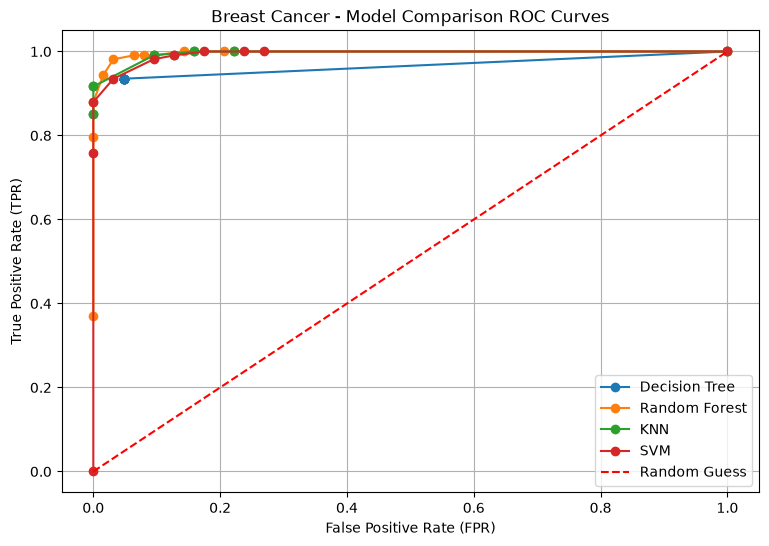

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
cancer_data = load_breast_cancer()
X = cancer_data.data
y = cancer_data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
dt_model = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
rf_model = RandomForestClassifier(random_state=42).fit(X_train, y_train)
knn_model = KNeighborsClassifier().fit(X_train, y_train)
svm_model = SVC(probability=True, random_state=42).fit(X_train, y_train)
models_probs = {
    'Decision Tree': dt_model.predict_proba(X_test)[:, 1],
    'Random Forest': rf_model.predict_proba(X_test)[:, 1],
    'KNN': knn_model.predict_proba(X_test)[:, 1],
    'SVM': svm_model.predict_proba(X_test)[:, 1]
}
actual_labels = list(y_test)
thresholds = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
plt.figure(figsize=(9, 6))
for model_name, predictions in models_probs.items():
    tpr_list = []
    fpr_list = []
    
    for threshold in thresholds:
        tp = 0
        tn = 0
        fp = 0
        fn = 0
        
        for i in range(len(actual_labels)):
            if predictions[i] >= threshold:
                pred = 1
            else:
                pred = 0
            if actual_labels[i] == 1 and pred == 1:
                tp += 1
            if actual_labels[i] == 0 and pred == 0:
                tn += 1
            if actual_labels[i] == 0 and pred == 1:
                fp += 1
            if actual_labels[i] == 1 and pred == 0:
                fn += 1      
        if (tp + fn) == 0:
            tpr = 0.0
        else:
            tpr = tp / (tp + fn)
            
        if (tn + fp) == 0:
            fpr = 0.0
        else:
            fpr = 1.0 - (tn / (tn + fp))
            
        tpr_list.append(tpr)
        fpr_list.append(fpr) 
    plt.plot(fpr_list, tpr_list, marker='o', label=f'{model_name}')
plt.plot([0, 1], [0, 1], linestyle='--', color='red', label='Random Guess')
plt.title('Breast Cancer - Model Comparison ROC Curves')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.grid(True)
plt.legend()
plt.show()